# Correlation Analysis of crime data vs NYC taxi pickups and dropoffs

## 1- Taxi Pickup/Dropoff vs Crime Type

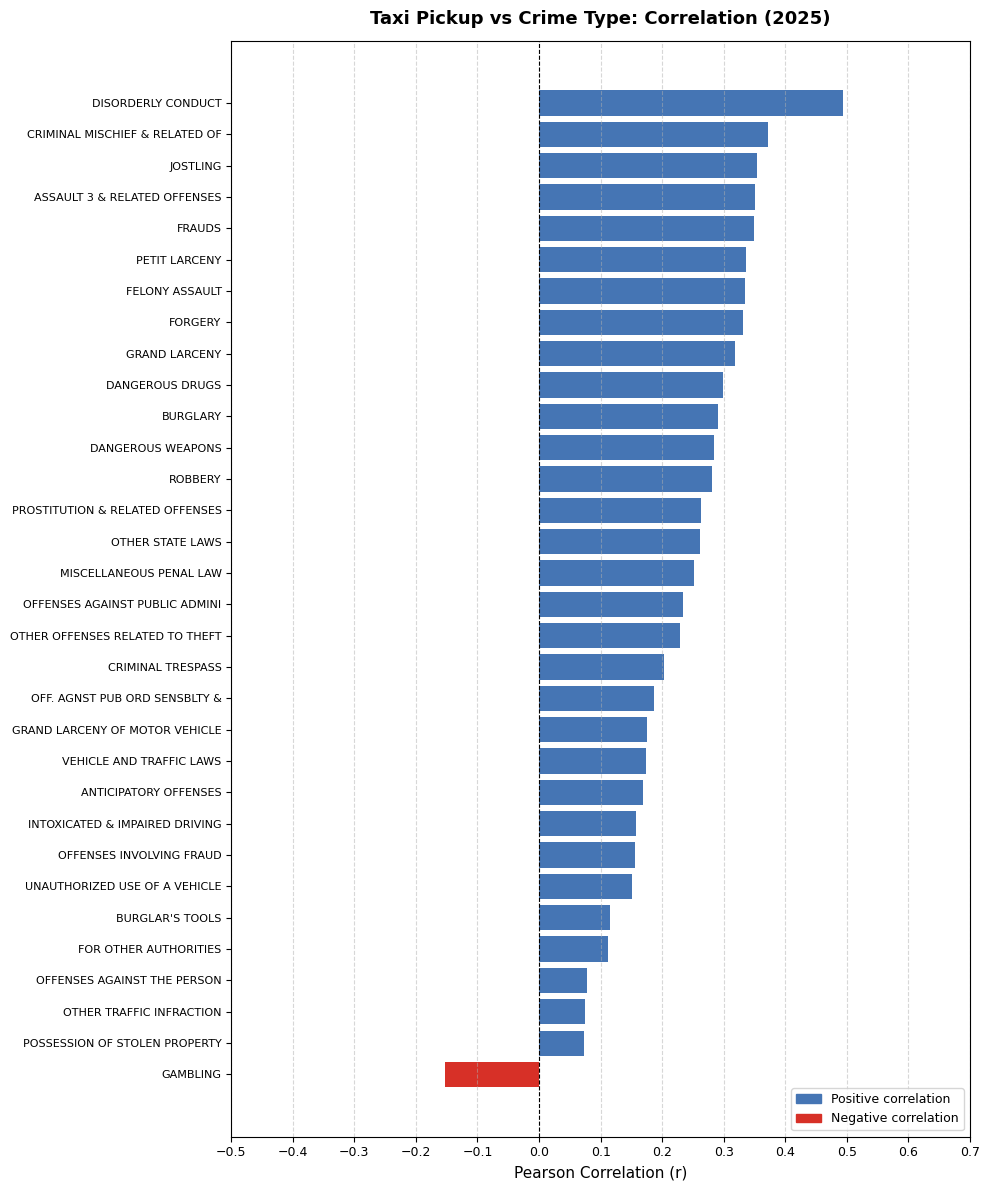

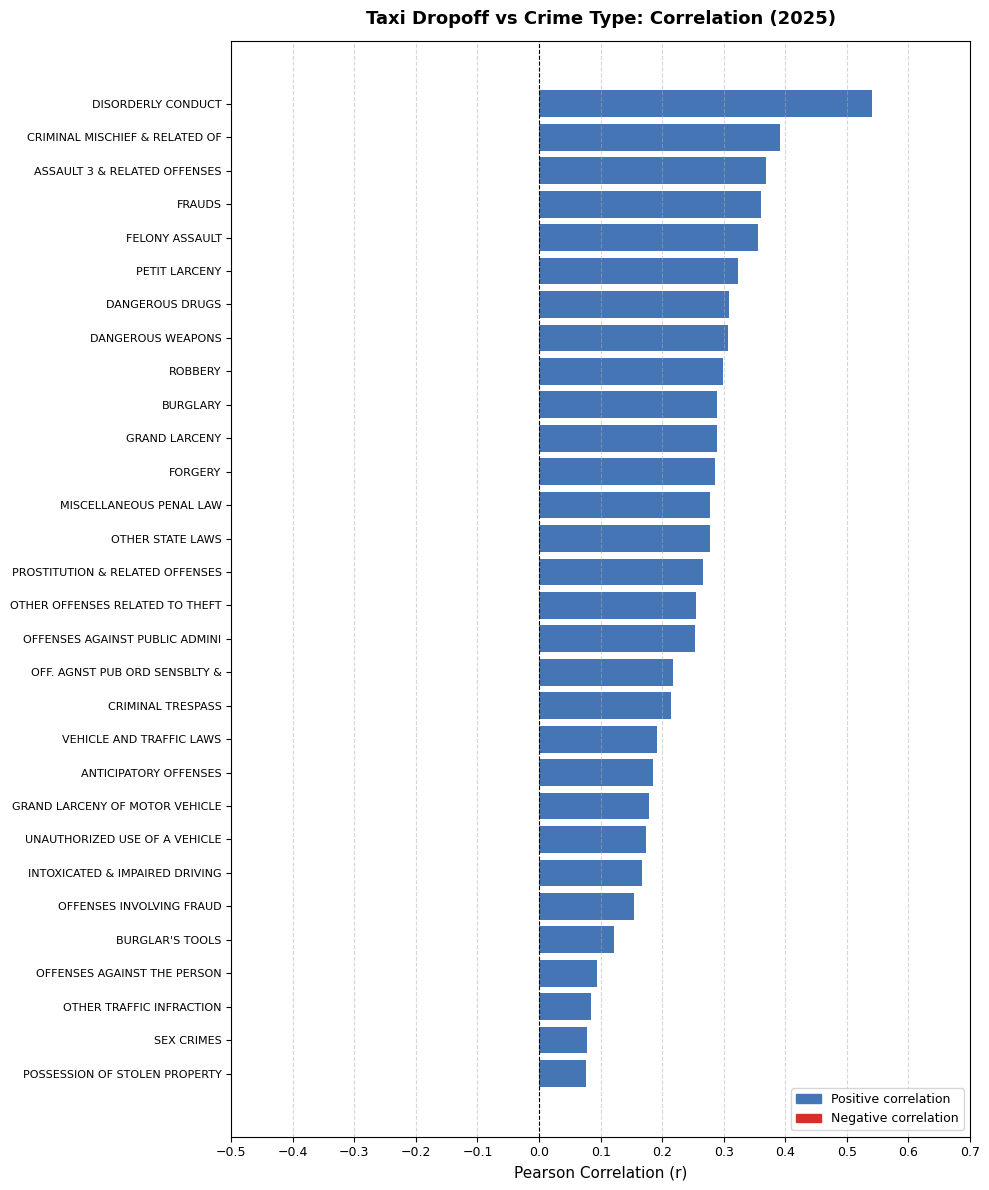

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_correlations(csv_path, title):
    """
    Plots a horizontal bar chart of the Pearson correlation values between taxi pickups/dropoffs and crime types.
    """
    df = pd.read_csv(csv_path)

    df = df[df["p_value"] < 0.05].copy()
    df = df.sort_values("correlation", ascending=True)

    bar_colours = []

    for correlation in df["correlation"]:
        if correlation < 0:
            bar_colours.append("#d73027")
        else:
            bar_colours.append("#4575b4")

    _, ax = plt.subplots(figsize=(10, 12))

    ax.barh(df["crime_group"], df["correlation"], color=bar_colours, edgecolor="none")

    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xlabel("Pearson Correlation (r)", fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", labelsize=9)
    ax.set_xlim(-0.5, 0.7)
    ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
    
    ticks = []
    for i in range(-5, 8):
        ticks.append(i / 10)
    ax.set_xticks(ticks)

    pos_patch = mpatches.Patch(color="#4575b4", label="Positive correlation")
    neg_patch = mpatches.Patch(color="#d73027", label="Negative correlation")
    ax.legend(handles=[pos_patch, neg_patch], fontsize=9, loc="lower right")

    plt.tight_layout()
    plt.show()

plot_correlations("crime_group_correlations_2025_pickup.csv", "Taxi Pickup vs Crime Type: Correlation (2025)")
plot_correlations("crime_group_correlations_2025_dropoff.csv","Taxi Dropoff vs Crime Type: Correlation (2025)")

## 2- Taxi Pickup vs Dropoff: Correlation with Crime Type

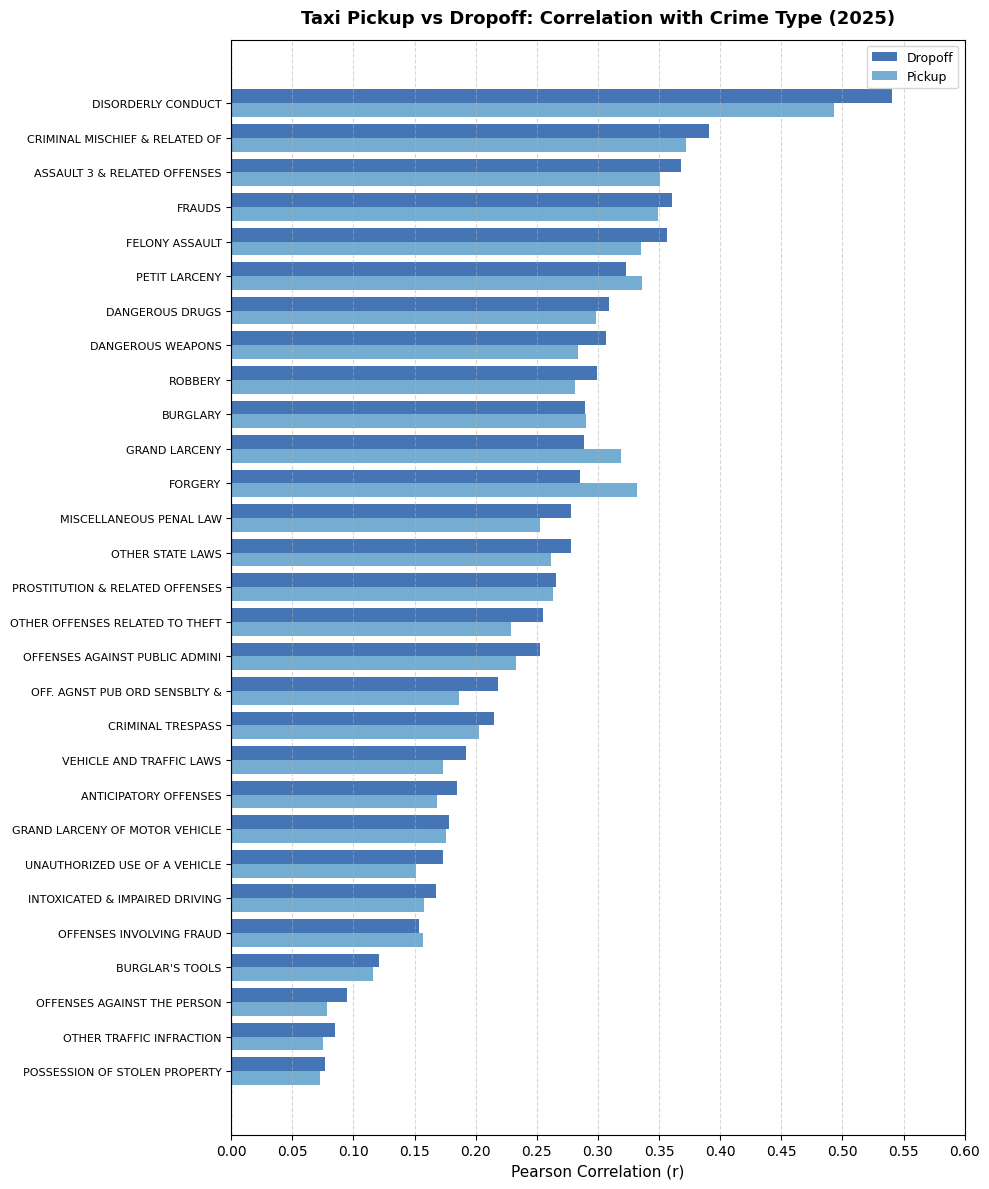

In [46]:
def plot_pickup_vs_dropoff(dropoff_path, pickup_path):
    """
    Plots a horizontal bar chart comparing the Pearson correlation values of taxi pickups and dropoffs with crime types.
    """
    df_drop = pd.read_csv(dropoff_path)
    df_pick = pd.read_csv(pickup_path)

    df_drop = df_drop[df_drop["p_value"] < 0.05][["crime_group", "correlation"]].rename(columns={"correlation": "dropoff"})
    df_pick = df_pick[df_pick["p_value"] < 0.05][["crime_group", "correlation"]].rename(columns={"correlation": "pickup"})

    df = pd.merge(df_drop, df_pick, on="crime_group").sort_values("dropoff", ascending=True)

    _, ax = plt.subplots(figsize=(10, 12))

    y = range(len(df))
    dropoff_positions = []
    pickup_positions = []

    for position in y:
        dropoff_positions.append(position + 0.2)
        pickup_positions.append(position - 0.2)

    ax.barh(dropoff_positions, df["dropoff"], height=0.4, label="Dropoff", color="#4575b4")
    ax.barh(pickup_positions, df["pickup"], height=0.4, label="Pickup", color="#74add1")

    ax.set_yticks(list(y))
    ax.set_yticklabels(df["crime_group"], fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
    
    ticks = []
    for i in range(0, 65, 5):
        ticks.append(i / 100)
    ax.set_xticks(ticks)

    ax.set_xlabel("Pearson Correlation (r)", fontsize=11)
    ax.set_title("Taxi Pickup vs Dropoff: Correlation with Crime Type (2025)", fontsize=13, fontweight="bold", pad=12)
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

plot_pickup_vs_dropoff("crime_group_correlations_2025_dropoff.csv", "crime_group_correlations_2025_pickup.csv")

## 3- Which Crime Types Correlate More with Dropoff vs Pickup?

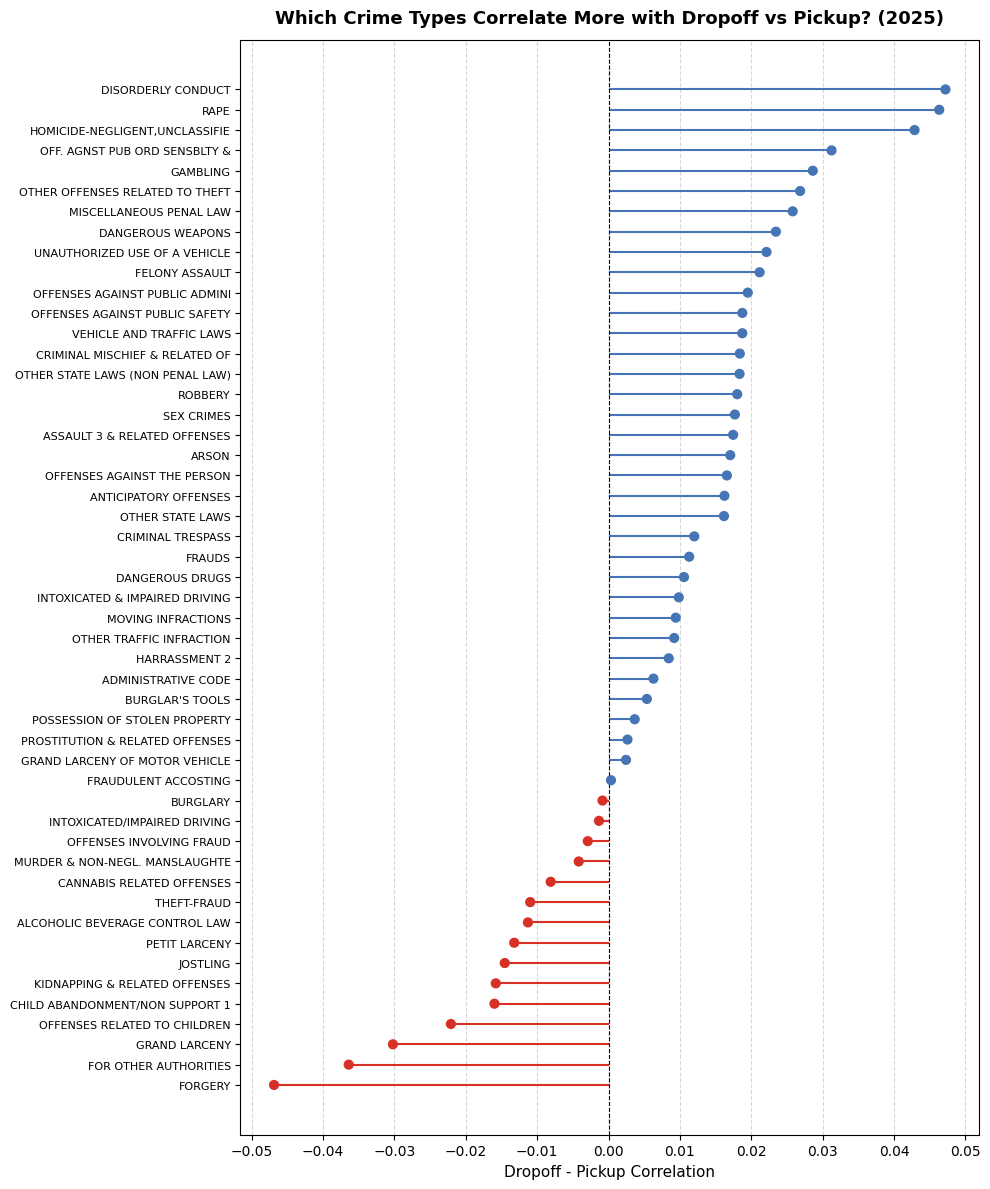

In [47]:
def plot_correlation_difference(dropoff_path, pickup_path):
    """
    Plots a horizontal bar chart showing the difference in Pearson correlation values between taxi dropoffs and pickups for each crime type.
    """
    df_drop = pd.read_csv(dropoff_path)[["crime_group", "correlation"]].rename(columns={"correlation": "dropoff"})
    df_pick = pd.read_csv(pickup_path)[["crime_group", "correlation"]].rename(columns={"correlation": "pickup"})

    df = pd.merge(df_drop, df_pick, on="crime_group")
    df["difference"] = df["dropoff"] - df["pickup"]
    df = df.sort_values("difference", ascending=True)

    bar_colours = []
    for diff in df["difference"]:
        if diff < 0:
            bar_colours.append("#d73027")
        else:
            bar_colours.append("#4575b4")

    _, ax = plt.subplots(figsize=(10, 12))

    ax.hlines(range(len(df)), 0, df["difference"], color=bar_colours, linewidth=1.5)
    ax.scatter(df["difference"], range(len(df)), color=bar_colours, s=40, zorder=3)

    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df["crime_group"], fontsize=8)
    ax.xaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)

    ticks = []
    for i in range(-5, 6, 1):
        ticks.append(i / 100)
    ax.set_xticks(ticks)

    ax.set_xlabel("Dropoff - Pickup Correlation", fontsize=11)
    ax.set_title("Which Crime Types Correlate More with Dropoff vs Pickup? (2025)", fontsize=13, fontweight="bold", pad=12)

    plt.tight_layout()
    plt.show()

plot_correlation_difference("crime_group_correlations_2025_dropoff.csv", "crime_group_correlations_2025_pickup.csv")